# v4 - Boneyard Creek (USGS 03337000): STIV con camara oblicua y sin geometria

Mide la velocidad superficial del agua en un video de la camara fija de la estacion de aforo de
Boneyard Creek (Urbana, Illinois), durante una crecida, con el STIV de la v3. Es el primer caso en
el que **no hay geometria de ningun tipo**: el data release del USGS (doi:10.5066/P9VZ6VYM) publica
61 videos y, para cada uno, el calado de escala `GH` y el caudal `Q` del limnigrafo. Nada mas: ni
puntos de control, ni ancho de canal, ni seccion, ni modelo de camara.

Sin escala no hay metros y sin seccion no hay caudal. Este notebook **no calcula caudal**: llega a
velocidad superficial en **alturas de camara por segundo**, que es lo que la geometria disponible
permite sostener.

**Los datos de entrada se leen en modo solo lectura. Todo lo que este notebook genera se escribe en
`salidas/`.** Las lineas de codigo que cambian respecto a la v3 llevan la marca `# [v4]`.

---
## Que cambia respecto a v3

| Parte | v3 (Sile Main Canal, STIV) | v4 (Boneyard Creek) | Por que lo obliga este caso |
|---|---|---|---|
| 0 | datos del workspace | busqueda de los **datasets externos** | los 61 videos (4.7 GB) no estan en el workspace |
| 1 | un video ya estabilizado | **triaje** de los 61 videos y medida de la vibracion | hay que elegir un video legible; la camara es fija y no hace falta estabilizar |
| 2 | escala por dos lineas de agua (vista cenital) | **punto de fuga** de las hiladas de los muros y **homografia**; escala en alturas de camara | camara oblicua y sin ninguna longitud conocida |
| 3 | una linea por vertical del aforo, girada `ANGULO_FLUJO` | `mapa_lineas` **generalizada** (cada linea con su centro): columnas del plano rectificado | sin seccion, las estaciones se reparten a lo ancho; en el plano rectificado el flujo es vertical |
| 3 | `V_ESPERADA` a ojo | `V_ESPERADA` por **correlacion de fase** | nadie tiene intuicion en alturas de camara por segundo |
| 4 | gris -> antialias -> muestreo | gris -> **rectificar** -> antialias -> muestreo | la escala cambia con la fila en una vista oblicua |
| 4 | derivadas: gaussiana `SIGMA_DERIVADA` = 1.5 + Sobel | **diferencias centrales** tras una gaussiana opcional; aqui `SIGMA_DERIVADA` = **0** | con el estimador de la v3 el perfil sale disperso (medido abajo); la textura es espuma fina |
| 4b | coherencia >= 0.70 | coherencia >= 0.70 **y contraste temporal >= 1.5** | los muros dan coherencia mas alta que el agua y velocidad cero: la coherencia sola los aprueba |
| 4b-5 | relleno lineal e integracion del caudal | **sin relleno y sin caudal**: perfil de velocidad | no hay seccion que integrar; rellenar seria inventar datos |
| 7 | aforo ADV | diagnostico con el `Q` del limnigrafo | no hay velocidad de referencia |

**Lo que no cambia:** la STI en una sola pasada, el paso de muestreo `DS` = desplazamiento por
fotograma y el antialias `DS/2`, `preparar_sti`, `medir_sti` (bloques de 64 con 50 % de solape y
mediana ponderada por coherencia, `COH_MIN_BLOQUE` = 0.50), `COH_MIN_ESTACION` = 0.70, los 250
fotogramas y el modulo `benchmark`.

---
## Parte 0 - Rutas de trabajo

Los videos del data release estan en la carpeta de datasets externos (46 GB, ver
`datos/externos/LEEME.md`). Se busca primero donde deberia estar (`datos/externos/`), luego en la
variable de entorno `DATASETS_VELOCIMETRIA` y por ultimo en la carpeta original de la que se
copio el workspace.

In [1]:
import os                                                                            # [v4]
from pathlib import Path

import benchmark  # modulo local (benchmark.py, en esta misma carpeta)


def buscar_datasets():
    """[v4] Carpeta 'datasets vision velocimetria', donde este."""
    candidatos = [Path("../../datos/externos/datasets vision velocimetria")]
    if os.environ.get("DATASETS_VELOCIMETRIA"):
        candidatos.append(Path(os.environ["DATASETS_VELOCIMETRIA"]))
    candidatos.append(Path("../../../test_pyorc-20261009T172625Z-1-001/test_pyorc/"
                           "datasets vision velocimetria"))
    for c in candidatos:
        if c.is_dir():
            return c
    raise SystemExit("No se encuentran los datasets externos: ver datos/externos/LEEME.md")


# --- Entradas (nunca se modifican) ---
DIR_DATOS = buscar_datasets() / "Boneyardcreek"                                     # [v4]
DIR_VIDEOS = DIR_DATOS / "boneyardcreek_video"                                      # [v4]
ARCHIVO_REGISTRO = DIR_DATOS / "boneyardcreek_video_records (2).csv"                # [v4] GH y Q
# [v4] Aguas bajas, con los dos muros al descubierto: de aqui sale la geometria.
ARCHIVO_CALIB = DIR_VIDEOS / "03337000_bullet_20180907-162000.mp4"
# [v4] El que se mide: el mayor caudal con luz diurna del dataset (ver Parte 1).
ARCHIVO_VIDEO = DIR_VIDEOS / "03337000_bullet_20180610-082000.mp4"

# --- Salidas ---
DIR_SALIDA = Path("salidas")
# exist_ok=True evita el error si la carpeta ya existe de una ejecucion anterior.
DIR_SALIDA.mkdir(exist_ok=True)

SALIDA_CONFIG = DIR_SALIDA / "config.json"                 # configuracion congelada
SALIDA_PERFIL = DIR_SALIDA / "perfil_velocidades.csv"      # velocidad estacion por estacion
SALIDA_RESUMEN = DIR_SALIDA / "velocidad_resumen.csv"      # [v4] tabla final (no hay caudal)
SALIDA_BENCHMARK = DIR_SALIDA / "benchmark_recursos.csv"   # coste de cada etapa

# Se vacian las mediciones por si el notebook se reejecuta sin reiniciar el kernel.
benchmark.reiniciar()

print("Datos de entrada:", DIR_DATOS)
print("Salidas en:      ", DIR_SALIDA)
# Se comprueba de una vez que las entradas existen, antes de procesar nada.
for entrada in (ARCHIVO_VIDEO, ARCHIVO_CALIB, ARCHIVO_REGISTRO):                    # [v4]
    print(f"  {'OK   ' if entrada.exists() else 'FALTA'} {entrada.name}")

Datos de entrada: ..\..\..\test_pyorc-20261009T172625Z-1-001\test_pyorc\datasets vision velocimetria\Boneyardcreek
Salidas en:       salidas
  OK    03337000_bullet_20180610-082000.mp4
  OK    03337000_bullet_20180907-162000.mp4
  OK    boneyardcreek_video_records (2).csv


---
## Parte 1 - Lectura del video

Se usan **dos** videos: el de **aguas bajas** (muros al descubierto) da la geometria, y el que se
mide es el del caudal **mas alto con luz diurna**. Calibrar en uno y medir en otro es legitimo: el
horizonte de un plano horizontal no depende de su altura, y es lo unico que la rectificacion
necesita.

Dimensiones del fotograma: (720, 1280, 3)
FPS del video: 22.4171  ->  DT = 44.609 ms
Fotogramas en el video: 867


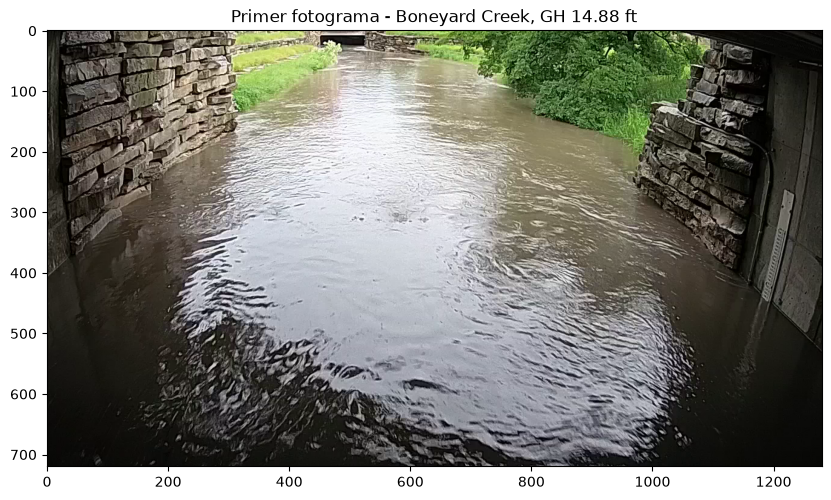

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# OpenCV: los metadatos y el primer fotograma del video que se mide.
cap = cv2.VideoCapture(str(ARCHIVO_VIDEO))
FPS = cap.get(cv2.CAP_PROP_FPS)
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
ok, frame_bgr = cap.read()
cap.release()
DT = 1.0 / FPS                    # intervalo entre fotogramas: entra en la velocidad
# OpenCV lee en BGR; matplotlib espera RGB.
frame = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

# Forma (filas, columnas, canales): las filas son la altura y las columnas el ancho.
print(f"Dimensiones del fotograma: {frame.shape}")
print(f"FPS del video: {FPS:.4f}  ->  DT = {DT * 1000:.3f} ms")
print(f"Fotogramas en el video: {N_TOTAL}")

plt.figure(figsize=(10, 6))
plt.imshow(frame)
plt.title("Primer fotograma - Boneyard Creek, GH 14.88 ft")                          # [v4]
plt.savefig(DIR_SALIDA / "fig1_fotograma.png", dpi=110, bbox_inches="tight")
plt.show()

### Triaje de los 61 videos

De noche la camara pasa a infrarrojo: en gris, desenfocada y con gotas en la lente, ilegible. La
**saturacion** de un fotograma central separa limpio los dos modos (el infrarrojo sale en gris).

In [3]:
# [v4] Celda nueva: triaje del dataset.
import pandas as pd

reg = pd.read_csv(ARCHIVO_REGISTRO)
reg["archivo"] = reg["filepath"].str.replace("\\", "/", regex=False).str.rsplit("/", n=1).str[-1]
with benchmark.medir("Parte 1: triaje de los 61 videos", n_frames=len(reg)):
    filas = []
    for _, r in reg.iterrows():
        cap = cv2.VideoCapture(str(DIR_VIDEOS / r.archivo))
        cap.set(cv2.CAP_PROP_POS_FRAMES, cap.get(cv2.CAP_PROP_FRAME_COUNT) // 2)
        ok, fr = cap.read()
        cap.release()
        if ok:
            filas.append(dict(archivo=r.archivo, hora=r.time, GH=r.GH, Q=r.Q,
                              brillo=cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY).mean(),
                              saturacion=cv2.cvtColor(fr, cv2.COLOR_BGR2HSV)[:, :, 1].mean()))
triaje = pd.DataFrame(filas)
# >>> AJUSTABLE <<< separan el modo diurno del infrarrojo nocturno: la saturacion es el
# discriminante; el brillo solo descarta los muy oscuros.
triaje["utilizable"] = (triaje.saturacion > 20) & (triaje.brillo > 40)
triaje.to_csv(DIR_SALIDA / "triaje_videos.csv", index=False)
ficha = triaje[triaje.archivo == ARCHIVO_VIDEO.name].iloc[0]
print(f"{triaje.utilizable.sum()} de {len(triaje)} videos utilizables (diurnos)")
print(triaje.nlargest(4, "Q")[["archivo", "hora", "Q", "saturacion", "utilizable"]]
      .to_string(index=False))
print(f"\nVideo a medir: {ficha.archivo}, GH = {ficha.GH} ft, Q = {ficha.Q} cfs "
      "(los dos caudales mayores son nocturnos)")

  [bench] Parte 1: triaje de los 61 videos: 42.6 s | CPU 178.8 s (4.2 nucleos) | RAM pico 231 MB
50 de 61 videos utilizables (diurnos)
                            archivo     hora     Q  saturacion  utilizable
03337000_bullet_20180815-201500.mp4 20:15:00 470.0    0.000000       False
03337000_bullet_20180509-201500.mp4 20:15:00 446.0    0.000000       False
03337000_bullet_20180610-082000.mp4  8:20:00 368.0   53.570107        True
03337000_bullet_20180820-201000.mp4 20:10:00 344.0    0.000000       False

Video a medir: 03337000_bullet_20180610-082000.mp4, GH = 14.88 ft, Q = 368.0 cfs (los dos caudales mayores son nocturnos)


### La camara no se mueve

Antes de decidir si hace falta estabilizar (en la v3 el video llegaba estabilizado), se mide la
vibracion **dentro** del video por correlacion de fase sobre un trozo de mamposteria seca.

In [4]:
# [v4] Celda nueva: vibracion de la camara.
# >>> AJUSTABLE <<< trozo de muro seco incluso con GH 14.88, usado como referencia fija
ROI_MURO = (slice(30, 330), slice(30, 300))


def _norm(a):
    a = a.astype(np.float32)
    return (a - a.mean()) / (a.std() + 1e-6)


cap = cv2.VideoCapture(str(ARCHIVO_VIDEO))
prev, vib = None, []
for _ in range(60):
    ok, fr = cap.read()
    g = _norm(cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY)[ROI_MURO])
    if prev is not None:
        vib.append(cv2.phaseCorrelate(prev, g)[0])
    prev = g
cap.release()
vib = np.abs(np.array(vib))
print(f"Vibracion entre fotogramas consecutivos: |dx| mediana {np.median(vib[:, 0]):.3f} px, "
      f"|dy| mediana {np.median(vib[:, 1]):.3f} px  -> no hace falta estabilizar")

Vibracion entre fotogramas consecutivos: |dx| mediana 0.018 px, |dy| mediana 0.051 px  -> no hace falta estabilizar


---
## Parte 2 - Geometria: punto de fuga y rectificacion

En la v3 la camara miraba hacia abajo y dos filas daban la escala. Aqui es oblicua: la escala cambia
con la fila y hay que **rectificar**. Sin puntos de control se usa el **punto de fuga longitudinal**
V1, donde concurren las hiladas de mamposteria de los dos muros (paralelas al eje del canal). Cada
segmento detectado define una recta homogenea `l = p1 x p2`, y V1 es el punto que mejor cumple
`l . V1 = 0` para todas; se resuelve con RANSAC, porque muchos segmentos son piedras sueltas.

Lo que basta con eso: una homografia que lleva el horizonte del plano de agua al infinito es,
respecto de ese plano, una **afinidad**, que escala por igual todas las longitudes de una misma
direccion. Como el flujo es longitudinal, **la velocidad sale correcta salvo una unica constante
global**: la altura de la camara sobre el agua, que es la unidad en la que queda todo. La focal es
cosmetica, y el **balanceo se supone nulo** (camara atornillada bajo una pasarela horizontal).

55 segmentos con orientacion de hilada, 17 concurren en V1
V1 = (653.0, -30.9) -> cabeceo 31.42 grados, guinada 0.99 grados
Plano rectificado: 1777x1080 px a 2.22 milesimas de altura de camara por px


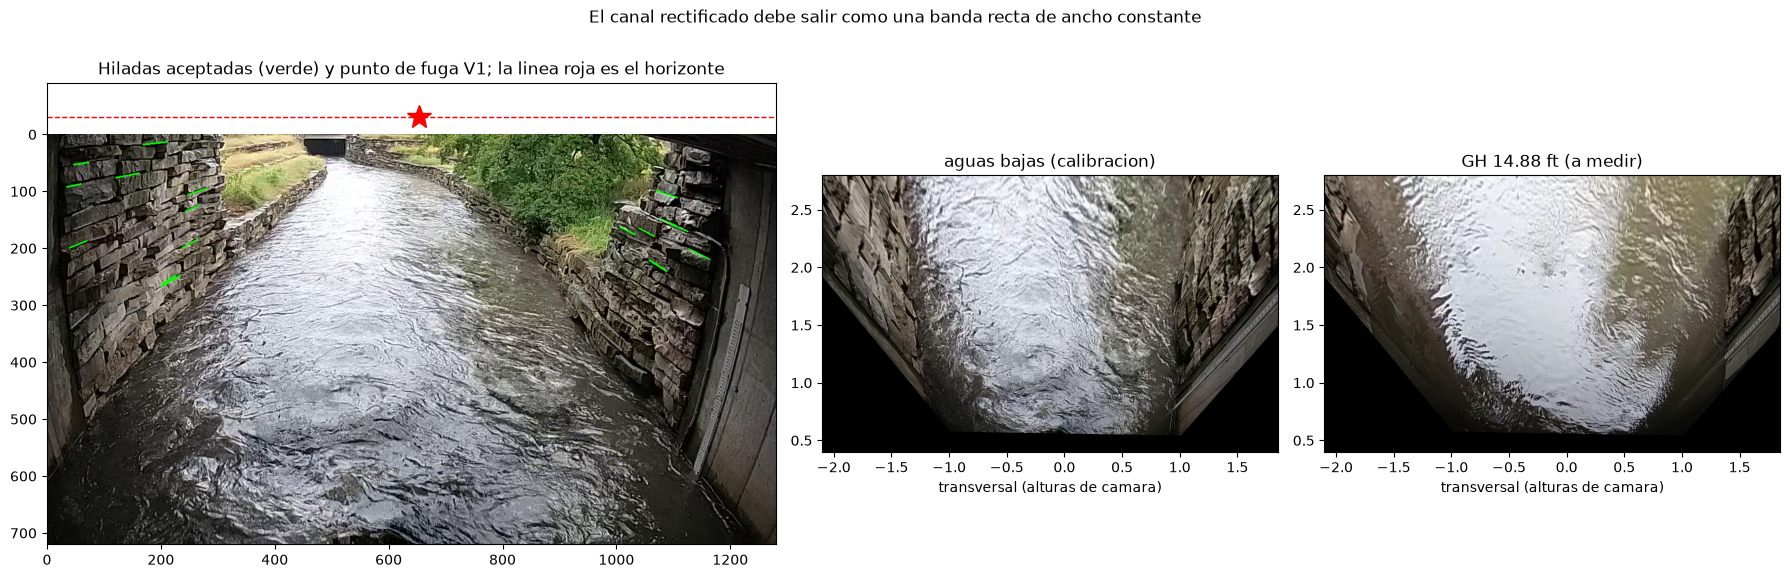

In [5]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Geometria de la escena                                           [v4]
# ---------------------------------------------------------------------------------------
MUROS = [(0, 0, 345, 480), (890, 40, 1190, 500)]   # regiones con hiladas fiables (x0,y0,x1,y1)
LARGO_MIN = 25                                     # longitud minima de segmento, px
FOCAL = 640.0                                      # cosmetica: solo cambia el aspecto
# Recorte del plano de agua, en alturas de camara. YMAX deja fuera la mitad lejana: cerca del
# horizonte un pixel de imagen cubre tanto terreno que el remuestreo borra la textura.
XMIN, XMAX = -2.10, 1.85
YMIN, YMAX = 0.40, 2.80
ESC = 450.0                                        # px del plano rectificado por altura de camara
# ---------------------------------------------------------------------------------------

cap = cv2.VideoCapture(str(ARCHIVO_CALIB))
cap.set(cv2.CAP_PROP_POS_FRAMES, cap.get(cv2.CAP_PROP_FRAME_COUNT) // 2)
_, frame_calib = cap.read()
cap.release()
ALTO_IMG, ANCHO_IMG = frame_calib.shape[:2]

segs = cv2.createLineSegmentDetector().detect(
    cv2.cvtColor(frame_calib, cv2.COLOR_BGR2GRAY))[0].reshape(-1, 4)
cx_s, cy_s = (segs[:, 0] + segs[:, 2]) / 2, (segs[:, 1] + segs[:, 3]) / 2
dentro = np.zeros(len(segs), bool)
for x0, y0, x1, y1 in MUROS:
    dentro |= (cx_s >= x0) & (cx_s < x1) & (cy_s >= y0) & (cy_s < y1)
largo = np.hypot(segs[:, 2] - segs[:, 0], segs[:, 3] - segs[:, 1])
segs = segs[dentro & (largo > LARGO_MIN)]
ang_s = np.degrees(np.arctan2(segs[:, 3] - segs[:, 1], segs[:, 2] - segs[:, 0])) % 180
hiladas = segs[(ang_s < 45) | (ang_s > 135)]


def punto_de_fuga(s, umbral=2.5, iters=3000, semilla=0):
    """[v4] Punto de fuga de un haz de segmentos, por RANSAC y ajuste final por SVD."""
    rng = np.random.default_rng(semilla)
    p1 = np.c_[s[:, 0], s[:, 1], np.ones(len(s))]
    p2 = np.c_[s[:, 2], s[:, 3], np.ones(len(s))]
    l = np.cross(p1, p2)
    l /= np.linalg.norm(l[:, :2], axis=1, keepdims=True)
    L = np.hypot(s[:, 2] - s[:, 0], s[:, 3] - s[:, 1])
    mejor, n_mejor = None, -1
    for _ in range(iters):
        i, j = rng.choice(len(l), 2, replace=False)
        v = np.cross(l[i], l[j])
        if abs(v[2]) < 1e-9:
            continue
        # el umbral se afloja para segmentos cortos: un mismo error angular desplaza mas el
        # punto de fuga cuanto mas corto es el segmento
        inl = np.abs(l @ v) / abs(v[2]) < umbral * (200.0 / np.maximum(L, 25))
        if inl.sum() > n_mejor:
            mejor, n_mejor = inl, inl.sum()
    _, _, vt = np.linalg.svd(l[mejor] * L[mejor, None])
    v = vt[-1] / vt[-1][2]
    return v[:2], mejor


def homografia(v1, focal, xmin, ymax, esc):
    """[v4] Imagen -> plano rectificado (px), con la altura de la camara como unidad."""
    cxi, cyi = ANCHO_IMG / 2, ALTO_IMG / 2
    theta = np.arctan((cyi - v1[1]) / focal)                 # cabeceo, del horizonte
    K = np.array([[focal, 0, cxi], [0, focal, cyi], [0, 0, 1.0]])
    R = np.array([[1, 0, 0],
                  [0, -np.sin(theta), -np.cos(theta)],
                  [0, np.cos(theta), -np.sin(theta)]])
    g2i = K @ np.column_stack([R[:, 0], R[:, 1], [0, np.cos(theta), np.sin(theta)]])
    d = R.T @ np.linalg.inv(K) @ np.array([v1[0], v1[1], 1.0])
    psi = np.arctan2(d[0], d[1])                             # guinada: canal vertical en la salida
    rot = np.array([[np.cos(psi), np.sin(psi), 0],
                    [-np.sin(psi), np.cos(psi), 0], [0, 0, 1.0]])
    S = np.array([[esc, 0, -xmin * esc], [0, -esc, ymax * esc], [0, 0, 1.0]])
    return S @ np.linalg.inv(g2i @ np.linalg.inv(rot)), np.degrees(theta), np.degrees(psi)


V1, inliers = punto_de_fuga(hiladas)
HOMOGRAFIA, CABECEO, GUINADA = homografia(V1, FOCAL, XMIN, YMAX, ESC)
TAM_RECT = (int((XMAX - XMIN) * ESC), int((YMAX - YMIN) * ESC))     # (ancho, alto) en px
ESCALA = 1.0 / ESC            # [v4] alturas de camara por px del plano rectificado
print(f"{len(hiladas)} segmentos con orientacion de hilada, {inliers.sum()} concurren en V1")
print(f"V1 = ({V1[0]:.1f}, {V1[1]:.1f}) -> cabeceo {CABECEO:.2f} grados, guinada {GUINADA:.2f} grados")
print(f"Plano rectificado: {TAM_RECT[0]}x{TAM_RECT[1]} px a {ESCALA * 1000:.2f} milesimas de "
      "altura de camara por px")

rect_calib = cv2.warpPerspective(frame_calib, HOMOGRAFIA, TAM_RECT)
rect_medida = cv2.warpPerspective(frame_bgr, HOMOGRAFIA, TAM_RECT)
fig, ax = plt.subplots(1, 3, figsize=(18, 6), gridspec_kw=dict(width_ratios=[1.6, 1, 1]))
vis = frame_calib.copy()
for k, (x1, y1, x2, y2) in enumerate(hiladas):
    cv2.line(vis, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0) if inliers[k] else
             (120, 120, 120), 2)
ax[0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
ax[0].plot(V1[0], V1[1], "r*", ms=18, clip_on=False)
ax[0].axhline(V1[1], color="r", ls="--", lw=1)
ax[0].set_ylim(ALTO_IMG, min(V1[1], 0) - 60)
ax[0].set_title("Hiladas aceptadas (verde) y punto de fuga V1; la linea roja es el horizonte")
for a, im, t in [(ax[1], rect_calib, "aguas bajas (calibracion)"),
                 (ax[2], rect_medida, f"GH {ficha.GH} ft (a medir)")]:
    a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB), extent=[XMIN, XMAX, YMIN, YMAX])
    a.set_title(t); a.set_xlabel("transversal (alturas de camara)")
fig.suptitle("El canal rectificado debe salir como una banda recta de ancho constante")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig2_geometria.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 3 - Lineas de busqueda

No hay seccion, asi que las estaciones se **reparten** a lo ancho del plano rectificado, y en ese
plano el flujo es vertical: cada linea de busqueda es una **columna**, muestreada de abajo arriba
(el agua se aleja de la camara). `mapa_lineas` se generaliza para que cada linea tenga su propio
centro: en la v3 todas compartian la columna central y solo cambiaba la fila.

`V_ESPERADA` sigue fijando el paso de muestreo, pero en alturas de camara por segundo nadie tiene
una estimacion a ojo, asi que se **mide** por correlacion de fase entre fotogramas rectificados
consecutivos, sobre una banda de agua. Es una estimacion previa, no el resultado.

V_ESPERADA = 0.2346 alturas de camara/s (correlacion de fase)
Desplazamiento esperado: 4.71 px/fotograma -> DS = 5 px, sigma antialias = 2.5 px, estelas a 43.3 grados
21 lineas de 216 muestras (2.40 alturas de camara cada una)


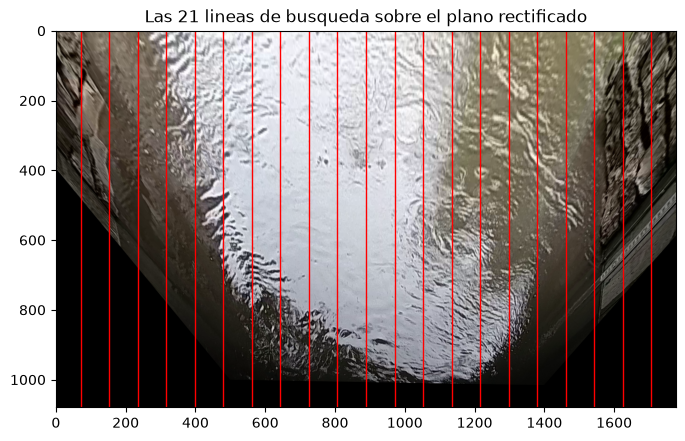

In [6]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Lineas de busqueda                                              [v4]
# ---------------------------------------------------------------------------------------
# Estaciones transversales, repartidas entre el 4 % y el 96 % del ancho del plano.
N_ESTACIONES = 21
# Direccion del flujo en el plano rectificado: hacia arriba (el agua se aleja de la camara).
ANGULO_FLUJO = -90.0          # grados
# ---------------------------------------------------------------------------------------

# [v4] V_ESPERADA medida por correlacion de fase sobre una banda de agua rectificada.
cap = cv2.VideoCapture(str(ARCHIVO_VIDEO))
cap.set(cv2.CAP_PROP_POS_FRAMES, 100)
prev, desp = None, []
for _ in range(40):
    ok, fr = cap.read()
    r = cv2.warpPerspective(cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY), HOMOGRAFIA, TAM_RECT)
    banda = _norm(r[int(TAM_RECT[1] * 0.65):int(TAM_RECT[1] * 0.85),
                    int(TAM_RECT[0] * 0.25):int(TAM_RECT[0] * 0.75)])
    if prev is not None:
        desp.append(cv2.phaseCorrelate(prev, banda)[0][1])
    prev = banda
cap.release()
V_ESPERADA = abs(float(np.median(desp))) * ESCALA / DT       # alturas de camara / s

# [v4] Estaciones: columnas del plano rectificado, centradas en su mitad vertical.
X_ESTACIONES = XMIN + np.linspace(0.04, 0.96, N_ESTACIONES) * (XMAX - XMIN)
centros = np.column_stack([(X_ESTACIONES - XMIN) / ESCALA, np.full(N_ESTACIONES, TAM_RECT[1] / 2)])
D_ESPERADO = V_ESPERADA * DT / ESCALA        # px por fotograma
DS = int(round(D_ESPERADO))                  # paso de muestreo: estelas a ~45 grados
SIGMA_ANTIALIAS = 0.5 * DS                   # filtro paso bajo obligatorio antes de submuestrear
print(f"V_ESPERADA = {V_ESPERADA:.4f} alturas de camara/s (correlacion de fase)")
print(f"Desplazamiento esperado: {D_ESPERADO:.2f} px/fotograma -> DS = {DS} px, "
      f"sigma antialias = {SIGMA_ANTIALIAS:.1f} px, estelas a "
      f"{np.degrees(np.arctan(D_ESPERADO / DS)):.1f} grados")


def mapa_lineas(centros, angulos_deg, ds, largo):
    """Coordenadas de muestreo de cada linea: mapx, mapy de forma (n_lineas, n_muestras).

    [v4] Cada linea tiene su centro (x, y) y su largo en px; en la v3 todas compartian la
    columna central de la imagen.
    """
    centros = np.atleast_2d(np.asarray(centros, float))
    angs = np.radians(np.broadcast_to(np.asarray(angulos_deg, float), (len(centros),)))
    n_mu = int(largo / ds)
    # t recorre la linea centrada en su punto medio, en pixeles
    t = (np.arange(n_mu) - (n_mu - 1) / 2) * ds
    mapx = np.zeros((len(centros), n_mu), np.float32)
    mapy = np.zeros((len(centros), n_mu), np.float32)
    for i, ((cx, cy), a) in enumerate(zip(centros, angs)):
        mapx[i] = cx + t * np.cos(a)
        mapy[i] = cy + t * np.sin(a)
    return mapx, mapy


mapx, mapy = mapa_lineas(centros, ANGULO_FLUJO, DS, TAM_RECT[1])                    # [v4]
print(f"{mapx.shape[0]} lineas de {mapx.shape[1]} muestras "
      f"({mapx.shape[1] * DS * ESCALA:.2f} alturas de camara cada una)")

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(rect_medida, cv2.COLOR_BGR2RGB))                            # [v4]
for i in range(N_ESTACIONES):
    plt.plot(mapx[i], mapy[i], "r-", lw=1)
plt.title(f"Las {N_ESTACIONES} lineas de busqueda sobre el plano rectificado")
plt.savefig(DIR_SALIDA / "fig3_lineas_busqueda.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4 - Velocidades superficiales con STIV

El mismo proceso que en la v3, con dos cambios:

1. **Rectificar antes de muestrear.** Cada fotograma se lleva al plano rectificado con
   `warpPerspective`; el antialias y el muestreo se hacen ya ahi, donde la escala es uniforme.
2. **Las derivadas del tensor.** La v3 suavizaba la STI con una gaussiana de sigma 1.5 y derivaba
   con Sobel 3x3, que suaviza ademas en la direccion perpendicular. Aqui el trazador es **espuma
   fina**, la textura mas pequena de la STI, y ese suavizado la borra frente a estructuras mas
   gruesas (ondas) que no viajan con la corriente: el perfil sale disperso. Se pasa a
   **diferencias centrales** (`np.gradient`) tras una gaussiana opcional, y aqui `SIGMA_DERIVADA`
   = 0. La celda siguiente lo mide, y comprueba que con el sigma de la v3 el nuevo operador da lo
   mismo que el viejo sobre las STI de la v3: el sigma es un parametro del caso, no del metodo.

Se guarda ademas el **contraste temporal** de cada estacion (la desviacion tipica en el tiempo,
mediana a lo largo de la linea) antes de normalizar, porque la Parte 4b lo necesita.

In [7]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Cuanto video se procesa y parametros del estimador
# ---------------------------------------------------------------------------------------
# 250 fotogramas a 22.4 fps son 11 s de video.
N_FRAMES = 250
# Lado del bloque de STI sobre el que se resuelve un tensor.
LADO_BLOQUE = 64
# Coherencia minima para que un bloque entre en la mediana ponderada.
COH_MIN_BLOQUE = 0.50
# [v4] Suavizado gaussiano previo a las derivadas, en pixeles de STI. 0 = sin suavizado: el
# trazador es espuma fina y es la textura mas pequena de la STI (la v3 usaba 1.5 con Sobel).
SIGMA_DERIVADA = 0.0
# ---------------------------------------------------------------------------------------


def construir_sti(archivo, mapx, mapy, n_frames, sigma, homografia=None, tam=None):
    """Apila n_frames filas muestreadas -> STI de forma (n_lineas, n_frames, n_muestras).

    [v4] Si se da una homografia, cada fotograma se rectifica antes del antialias.
    """
    cap = cv2.VideoCapture(str(archivo))
    sti = np.zeros((mapx.shape[0], n_frames, mapx.shape[1]), np.float32)
    for k in range(n_frames):
        ok, fr = cap.read()
        if not ok:
            sti = sti[:, :k, :]
            break
        gris = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY).astype(np.float32)
        if homografia is not None:                                                   # [v4]
            gris = cv2.warpPerspective(gris, homografia, tam)
        # Antialias ANTES de muestrear: sin esto el submuestreo inventa orientaciones.
        gris = cv2.GaussianBlur(gris, (0, 0), sigma)
        sti[:, k, :] = cv2.remap(gris, mapx, mapy, cv2.INTER_LINEAR)
    cap.release()
    return sti


def preparar_sti(sti):
    """Quita el fondo estatico y el parpadeo global, y normaliza."""
    a = sti - sti.mean(axis=0, keepdims=True)   # fondo fijo de cada muestra (rayas verticales)
    a = a - a.mean(axis=1, keepdims=True)       # parpadeo de cada fotograma (rayas horizontales)
    d = a.std()
    return a / d if d > 0 else a


def tensor_estructura(bloque, sigma=SIGMA_DERIVADA):
    """Pendiente m (muestras/fotograma) y coherencia C de un trozo de STI."""
    # [v4] Gaussiana opcional y diferencias centrales, en lugar de gaussiana + Sobel 3x3.
    g = cv2.GaussianBlur(bloque, (0, 0), sigma) if sigma > 0 else bloque
    # eje 0 = tiempo (filas), eje 1 = espacio (columnas)
    It, Ix = np.gradient(g)
    Jxx = float((Ix * Ix).sum())
    Jtt = float((It * It).sum())
    Jxt = float((Ix * It).sum())
    if Jxx + Jtt <= 0:
        return np.nan, 0.0
    # autovector del autovalor MENOR = direccion a lo largo de las estelas
    _, vec = np.linalg.eigh(np.array([[Jxx, Jxt], [Jxt, Jtt]]))
    ex, et = vec[:, 0]
    if et < 0:            # el autovector esta definido salvo signo: se orienta hacia t creciente
        ex, et = -ex, -et
    m = ex / et if et != 0 else np.nan
    coherencia = np.sqrt((Jxx - Jtt) ** 2 + 4 * Jxt ** 2) / (Jxx + Jtt)
    return m, float(coherencia)


def medir_sti(sti_p, lado=LADO_BLOQUE, coh_min=COH_MIN_BLOQUE, sigma=SIGMA_DERIVADA):
    """Pendiente robusta de una STI, por bloques con solape: (m, coherencia mediana)."""
    nt, nx = sti_p.shape
    paso = lado // 2
    ms, cs = [], []
    for t0 in range(0, nt - lado + 1, paso):
        for x0 in range(0, nx - lado + 1, paso):
            m, c = tensor_estructura(sti_p[t0:t0 + lado, x0:x0 + lado], sigma)   # [v4]
            if np.isfinite(m):
                ms.append(m); cs.append(c)
    if not ms:
        return np.nan, 0.0
    ms, cs = np.array(ms), np.array(cs)
    coh_mediana = float(np.median(cs))
    usables = cs >= coh_min
    if usables.sum() == 0:
        return np.nan, coh_mediana
    # mediana ponderada por coherencia: los bloques nitidos pesan mas
    mm, cc = ms[usables], cs[usables]
    orden = np.argsort(mm)
    mm, cc = mm[orden], cc[orden]
    acumulado = np.cumsum(cc) / cc.sum()
    return float(mm[np.searchsorted(acumulado, 0.5)]), coh_mediana


# Unica pasada sobre el video: el bloque caro del notebook.
with benchmark.medir("Parte 4: construir las STI", n_frames=N_FRAMES):
    sti_crudo = construir_sti(ARCHIVO_VIDEO, mapx, mapy, N_FRAMES, SIGMA_ANTIALIAS,
                              HOMOGRAFIA, TAM_RECT)                                 # [v4]
np.save(DIR_SALIDA / "sti_crudo.npy", sti_crudo)
# [v4] Contraste temporal de cada estacion, antes de normalizar: lo usa la Parte 4b.
CONTRASTE = np.median(sti_crudo.std(axis=1), axis=1)

with benchmark.medir("Parte 4: preparar STI + tensor de estructura"):
    sti_prep = np.stack([preparar_sti(s) for s in sti_crudo])
    v_stiv = np.full(N_ESTACIONES, np.nan)
    coherencia = np.full(N_ESTACIONES, np.nan)
    for i in range(N_ESTACIONES):
        m, coherencia[i] = medir_sti(sti_prep[i])
        v_stiv[i] = m * DS * ESCALA / DT if np.isfinite(m) else np.nan

print(f"STI: {sti_crudo.shape[0]} lineas x {sti_crudo.shape[1]} fotogramas x "
      f"{sti_crudo.shape[2]} muestras")
print(pd.DataFrame({"estacion": np.arange(N_ESTACIONES), "x": X_ESTACIONES,
                    "contraste": CONTRASTE, "coherencia": coherencia,
                    "v_alt_cam_s": v_stiv})
      .to_string(index=False, float_format=lambda x: f"{x:8.4f}"))

  [bench] Parte 4: construir las STI: 14.7 s | CPU 57.0 s (3.9 nucleos) | RAM pico 301 MB


  [bench] Parte 4: preparar STI + tensor de estructura: 0.2 s | CPU 0.2 s (1.0 nucleos) | RAM pico 218 MB
STI: 21 lineas x 250 fotogramas x 216 muestras
 estacion        x  contraste  coherencia  v_alt_cam_s
        0  -1.9420     0.0000      0.8272       0.0003
        1  -1.7603     0.9412      0.5398       0.0022
        2  -1.5786     1.3597      0.4412       0.1859
        3  -1.3969     4.7651      0.6468       0.2634
        4  -1.2152    10.3762      0.6717       0.2682
        5  -1.0335    20.8891      0.6449       0.2462
        6  -0.8518    14.7592      0.7026       0.2414
        7  -0.6701    10.3180      0.7209       0.2484
        8  -0.4884     7.5951      0.6926       0.2525
        9  -0.3067     7.7429      0.7392       0.2650
       10  -0.1250     8.3217      0.6884       0.2328
       11   0.0567     8.2756      0.7565       0.2375
       12   0.2384    18.4911      0.7218       0.2238
       13   0.4201    20.2978      0.7629       0.2252
       14   0.6018    

In [8]:
# [v4] Celda nueva: por que cambian las derivadas. Se mide con el estimador de la v3
# (gaussiana 1.5 + Sobel) y con el de esta version, sobre estas STI y sobre las de la v3.
def tensor_v3(bloque, sigma=1.5):
    g = cv2.GaussianBlur(bloque, (0, 0), sigma)
    It = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)[2:-2, 2:-2]
    Ix = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)[2:-2, 2:-2]
    Jxx, Jtt, Jxt = float((Ix * Ix).sum()), float((It * It).sum()), float((Ix * It).sum())
    _, vec = np.linalg.eigh(np.array([[Jxx, Jxt], [Jxt, Jtt]]))
    ex, et = vec[:, 0] if vec[1, 0] >= 0 else -vec[:, 0]
    if et == 0:
        return np.nan, 0.0
    return ex / et, float(np.sqrt((Jxx - Jtt) ** 2 + 4 * Jxt ** 2) / (Jxx + Jtt))


def medir_con(sti_p, tensor, sigma):
    """medir_sti con otro estimador por bloque (solo para esta comparacion)."""
    global tensor_estructura
    original = tensor_estructura
    tensor_estructura = tensor
    try:
        return medir_sti(sti_p, sigma=sigma)
    finally:
        tensor_estructura = original


agua = CONTRASTE >= 1.5
comp = pd.DataFrame({
    "x": X_ESTACIONES,
    "v3: gaussiana 1.5 + Sobel": [medir_con(s, tensor_v3, 1.5)[0] for s in sti_prep],
    "v4 con sigma 1.5": [medir_sti(s, sigma=1.5)[0] for s in sti_prep],
    "v4 con sigma 0 (esta version)": [medir_sti(s, sigma=0.0)[0] for s in sti_prep],
})[agua]
for col in comp.columns[1:]:
    comp[col] = comp[col] * DS * ESCALA / DT
print("Velocidad (alturas de camara/s) en las estaciones sobre agua:")
print(comp.to_string(index=False, float_format=lambda x: f"{x:7.4f}"))
print("\nDispersion entre estaciones vecinas (desv. tipica de la diferencia):")
for col in comp.columns[1:]:
    print(f"  {col:32s} {np.nanstd(np.diff(comp[col].to_numpy())):.4f}")

# Regresion: el nuevo operador sobre las STI de la v3 (Sile Main Canal), si existen.
ARCHIVO_STI_V3 = Path("../v3_smc_stiv/salidas/sti_crudo.npy")
if ARCHIVO_STI_V3.exists():
    sti_v3 = np.load(ARCHIVO_STI_V3)
    print("\nSobre las STI de la v3 (pendiente, muestras/fotograma, verticales 1 a 11):")
    for nombre, f in [("v3: gaussiana 1.5 + Sobel", lambda s: medir_con(s, tensor_v3, 1.5)),
                      ("v4 con sigma 1.5", lambda s: medir_sti(s, sigma=1.5)),
                      ("v4 con sigma 0", lambda s: medir_sti(s, sigma=0.0))]:
        print(f"  {nombre:28s}", np.round([f(preparar_sti(s))[0] for s in sti_v3[1:12]], 3))
    print("Con el sigma de la v3, el operador nuevo da lo mismo sobre el Sile; con sigma 0 el")
    print("perfil del Sile se aplana. El suavizado depende de la textura de cada caso.")

Velocidad (alturas de camara/s) en las estaciones sobre agua:
      x  v3: gaussiana 1.5 + Sobel  v4 con sigma 1.5  v4 con sigma 0 (esta version)
-1.3969                     0.2446            0.2478                         0.2634
-1.2152                     2.1059           13.5808                         0.2682
-1.0335                     1.8703            0.2133                         0.2462
-0.8518                     0.2445            0.2420                         0.2414
-0.6701                     0.3034            0.2964                         0.2484
-0.4884                     0.2499            0.2488                         0.2525
-0.3067                     0.2727            0.2555                         0.2650
-0.1250                     0.1768            0.2062                         0.2328
 0.0567                     0.2770            0.2681                         0.2375
 0.2384                     0.1545            0.1645                         0.2238
 0.4201       

  v4 con sigma 1.5             [0.581 0.76  0.885 0.933 0.995 1.013 0.974 0.997 0.943 0.918 1.312]
  v4 con sigma 0               [0.808 0.924 0.971 0.979 0.998 1.004 0.996 0.994 0.988 0.971 1.003]
Con el sigma de la v3, el operador nuevo da lo mismo sobre el Sile; con sigma 0 el
perfil del Sile se aplana. El suavizado depende de la textura de cada caso.


---
## Parte 4b - Control de calidad

**El umbral de coherencia de la v3 no basta, y aqui es contraproducente.** Las estaciones que caen
sobre los muros dan **coherencia mas alta que el agua con velocidad exactamente cero**: una
estructura estatica es una estela perfectamente coherente de pendiente nula. Un umbral de coherencia
no las rechaza, las aprueba.

El discriminante es el **contraste temporal**: un muro no cambia con el tiempo. El umbral no se elige
a ojo, se lee de los datos: hay un hueco limpio entre lo estatico y lo que fluye, y `CONTRASTE_MIN`
= 1.5 cae en el.

**No se rellena.** En la v3 los huecos se interpolaban porque habia que integrar un caudal. Aqui no
hay seccion: rellenar solo serviria para inventar datos. Las rechazadas quedan como huecos.

  [bench] Parte 4b: control de calidad: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 220 MB
Estaciones medidas: 9 de 21
Coherencia de las estaciones sobre muro: [0.827 0.54  0.441 0.86  0.839] (las del agua: mediana 0.712)
Sin el criterio de contraste, el umbral de coherencia aprobaria 3 estaciones de muro con v ~ 0.


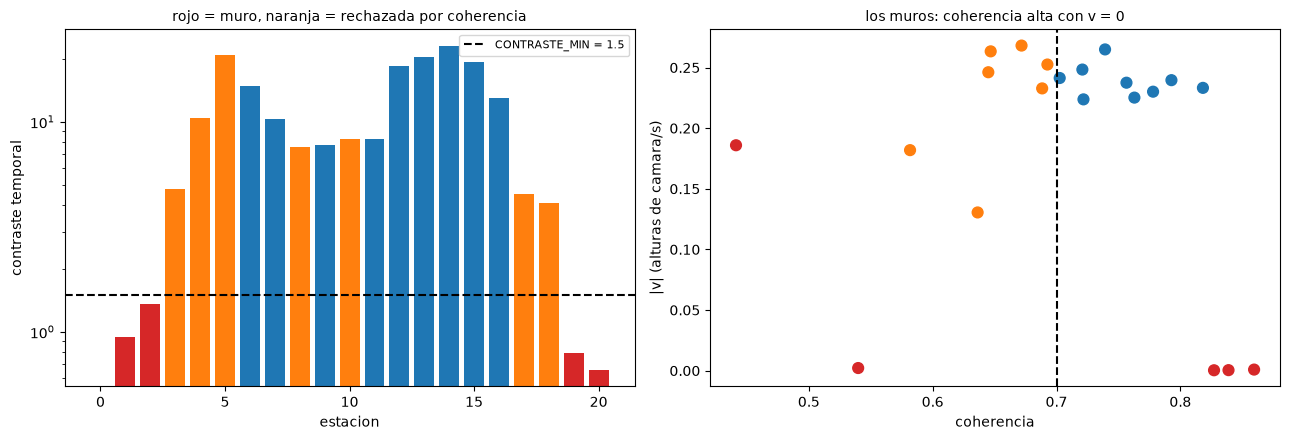

In [9]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Criterios de aceptacion
# ---------------------------------------------------------------------------------------
# Coherencia mediana minima para dar por buena una estacion. La misma de la v3.
COH_MIN_ESTACION = 0.70
# [v4] Desviacion temporal minima de la STI cruda, en niveles de gris: separa muro de agua.
CONTRASTE_MIN = 1.5
# ---------------------------------------------------------------------------------------

with benchmark.medir("Parte 4b: control de calidad"):
    es_estatica = CONTRASTE < CONTRASTE_MIN                                          # [v4]
    medida = (~es_estatica) & (coherencia >= COH_MIN_ESTACION) & np.isfinite(v_stiv)  # [v4]
    v_eff = np.where(medida, v_stiv, np.nan)                                         # [v4]

print(f"Estaciones medidas: {int(medida.sum())} de {N_ESTACIONES}")
print(f"Coherencia de las estaciones sobre muro: {np.round(coherencia[es_estatica], 3)} "
      f"(las del agua: mediana {np.median(coherencia[~es_estatica]):.3f})")
print("Sin el criterio de contraste, el umbral de coherencia aprobaria "
      f"{int((es_estatica & (coherencia >= COH_MIN_ESTACION)).sum())} estaciones de muro con v ~ 0.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
col = np.where(es_estatica, "tab:red", np.where(medida, "tab:blue", "tab:orange"))
ax[0].bar(range(N_ESTACIONES), CONTRASTE, color=col)
ax[0].axhline(CONTRASTE_MIN, ls="--", c="k", label=f"CONTRASTE_MIN = {CONTRASTE_MIN}")
ax[0].set_yscale("log"); ax[0].set_xlabel("estacion"); ax[0].set_ylabel("contraste temporal")
ax[0].set_title("rojo = muro, naranja = rechazada por coherencia", fontsize=10)
ax[0].legend(fontsize=8)
ax[1].scatter(coherencia, np.abs(v_stiv), c=col, s=60)
ax[1].axvline(COH_MIN_ESTACION, ls="--", c="k")
ax[1].set_xlabel("coherencia"); ax[1].set_ylabel("|v| (alturas de camara/s)")
ax[1].set_title("los muros: coherencia alta con v = 0", fontsize=10)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig4_control_calidad.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 5 - Perfil transversal de velocidad superficial

Aqui termina la medida: sin seccion no hay caudal (Parte 7). Las unidades son **alturas de camara
por segundo**, correctas salvo una constante global, y se convierten a m/s multiplicando por la
altura real de la camara sobre el agua el dia que se conozca.

  [bench] Parte 5: perfil transversal: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 234 MB
Velocidad superficial mediana: 0.2375 alturas de camara/s
  q05-q95: 0.2244 - 0.2583
Estaciones medidas: 9 de 21 (sin relleno)


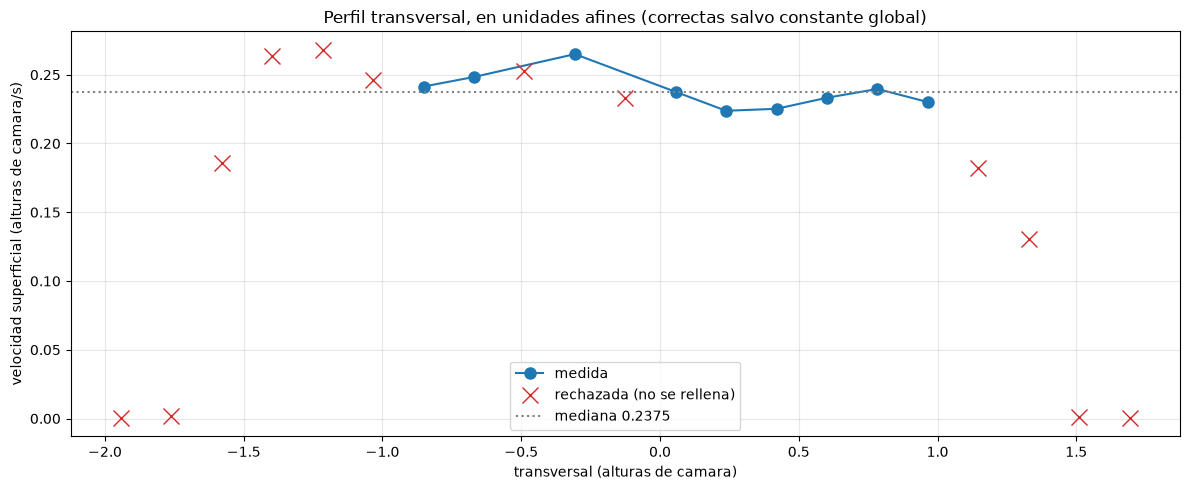

,estacion,x_alt_cam,contraste,coherencia,v_medida_alt_cam_s,estado
0,0,-1.9420,0.000000,0.827198,NaN,muro (estatica)
1,1,-1.7603,0.941206,0.539831,NaN,muro (estatica)
2,2,-1.5786,1.359699,0.441186,NaN,muro (estatica)
3,3,-1.3969,4.765143,0.646846,NaN,coherencia baja
4,4,-1.2152,10.376190,0.671747,NaN,coherencia baja
5,5,-1.0335,20.889145,0.644929,NaN,coherencia baja
6,6,-0.8518,14.759162,0.702572,0.241404,medida
7,7,-0.6701,10.317972,0.720876,0.248373,medida
8,8,-0.4884,7.595112,0.692640,NaN,coherencia baja
9,9,-0.3067,7.742867,0.739201,0.264981,medida


In [10]:
with benchmark.medir("Parte 5: perfil transversal"):                                # [v4]
    v_mediana = float(np.nanmedian(v_eff))
    v_q05, v_q95 = np.nanquantile(v_eff, [0.05, 0.95])

print("=" * 52)
print(f"Velocidad superficial mediana: {v_mediana:.4f} alturas de camara/s")         # [v4]
print(f"  q05-q95: {v_q05:.4f} - {v_q95:.4f}")
print(f"Estaciones medidas: {int(medida.sum())} de {N_ESTACIONES} (sin relleno)")
print("=" * 52)

perfil = pd.DataFrame({
    "estacion": np.arange(N_ESTACIONES),
    "x_alt_cam": X_ESTACIONES,                                                          # [v4]
    "contraste": CONTRASTE,                                                            # [v4]
    "coherencia": coherencia,
    "v_medida_alt_cam_s": v_eff,                                                       # [v4]
    "estado": np.where(medida, "medida",
                       np.where(es_estatica, "muro (estatica)", "coherencia baja")),   # [v4]
})
perfil.to_csv(SALIDA_PERFIL, index=False)

import json
config = dict(video=ARCHIVO_VIDEO.name, video_calibracion=ARCHIVO_CALIB.name,
              n_frames=N_FRAMES, fps=FPS, v1=[float(V1[0]), float(V1[1])], focal=FOCAL,
              cabeceo=CABECEO, guinada=GUINADA, xmin=XMIN, xmax=XMAX, ymin=YMIN, ymax=YMAX,
              esc_px_por_altura=ESC, n_estaciones=N_ESTACIONES, angulo_flujo=ANGULO_FLUJO,
              v_esperada=V_ESPERADA, ds_px=DS, sigma_antialias=SIGMA_ANTIALIAS,
              lado_bloque=LADO_BLOQUE, coh_min_bloque=COH_MIN_BLOQUE,
              sigma_derivada=SIGMA_DERIVADA, coh_min_estacion=COH_MIN_ESTACION,
              contraste_min=CONTRASTE_MIN, v_mediana_alt_cam_s=v_mediana)
SALIDA_CONFIG.write_text(json.dumps(config, indent=2), encoding="utf-8")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(X_ESTACIONES[medida], v_eff[medida], "o-", color="tab:blue", ms=8, label="medida")
ax.plot(X_ESTACIONES[~medida], np.abs(v_stiv[~medida]), "x", color="tab:red", ms=11,
        label="rechazada (no se rellena)")
ax.axhline(v_mediana, ls=":", c="gray", label=f"mediana {v_mediana:.4f}")
ax.set_xlabel("transversal (alturas de camara)")
ax.set_ylabel("velocidad superficial (alturas de camara/s)")
ax.set_title("Perfil transversal, en unidades afines (correctas salvo constante global)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig5_perfil.png", dpi=110, bbox_inches="tight")
plt.show()
perfil

---
## Parte 6 - Recursos consumidos

Columnas: **segundos** de reloj; **cpu_s** y **nucleos** (CPU sumando todos los nucleos y su cociente
con el reloj); **ram_pico_mb**, el maximo de memoria residente durante la etapa; y **ram_neta_mb**.

Frente a la v3 el video es 720p, ocho veces menos pixeles que el 4K del Sile, pero aparece un coste
que alli no existia: **rectificar** cada fotograma antes de muestrear.

Maquina donde se han medido los tiempos:
  cpu_nucleos_fisicos: 12
  cpu_nucleos_logicos: 16
  ram_total_gb: 42.7
  ram_disponible_gb: 20.3

Tiempo total medido: 57.6 s
Pico de memoria del proceso: 301 MB


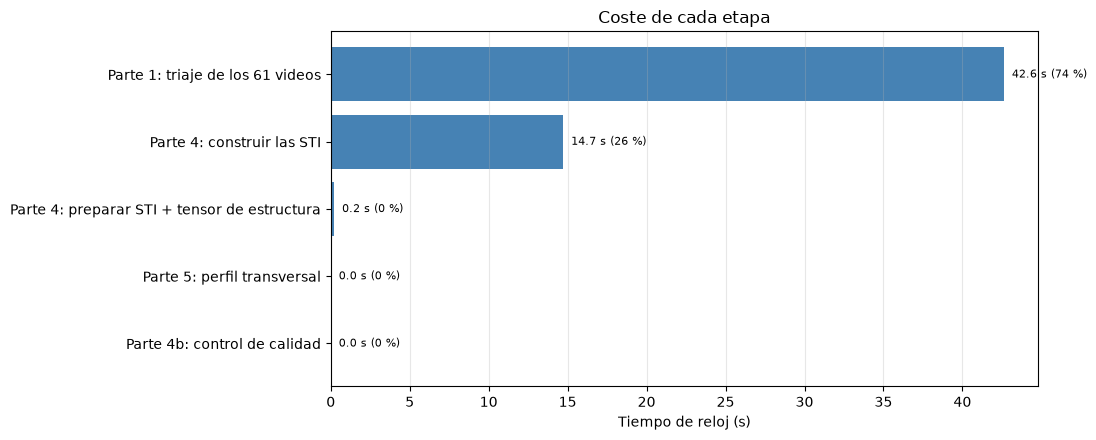

,etapa,segundos,cpu_s,nucleos,ram_pico_mb,ram_neta_mb,n_frames,pct_tiempo
0,Parte 1: triaje de los 61 videos,42.63,178.77,4.19,231.4,6.0,61.0,74.1
1,Parte 4: construir las STI,14.72,57.00,3.87,301.0,-34.5,250.0,25.6
2,Parte 4: preparar STI + tensor de estructura,0.21,0.22,1.03,217.8,3.5,NaN,0.4
3,Parte 4b: control de calidad,0.00,0.00,0.00,220.2,0.0,NaN,0.0
4,Parte 5: perfil transversal,0.00,0.00,0.00,234.2,0.0,NaN,0.0


In [11]:
print("Maquina donde se han medido los tiempos:")
for k, v in benchmark.entorno().items():
    print(f"  {k}: {v}")

tabla_recursos = benchmark.tabla()
tabla_recursos.to_csv(SALIDA_BENCHMARK, index=False)
print(f"\nTiempo total medido: {tabla_recursos['segundos'].sum():.1f} s")
print(f"Pico de memoria del proceso: {tabla_recursos['ram_pico_mb'].max():.0f} MB")

fig, ax = plt.subplots(figsize=(11, 4.5))
orden = tabla_recursos.sort_values("segundos")
ax.barh(orden["etapa"], orden["segundos"], color="steelblue")
ax.set_xlabel("Tiempo de reloj (s)")
ax.set_title("Coste de cada etapa")
ax.grid(axis="x", alpha=0.3)
for y, (seg, pct) in enumerate(zip(orden["segundos"], orden["pct_tiempo"])):
    ax.text(seg, y, f"  {seg:.1f} s ({pct:.0f} %)", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig6_recursos.png", dpi=110, bbox_inches="tight")
plt.show()
tabla_recursos

---
## Parte 7 - Contraste con el limnigrafo, y que falta para cerrar caudal

Aqui este caso se separa de la v3: **no se puede cerrar**. El limnigrafo da `Q` y `GH` para este
video, pero para convertir la velocidad en caudal harian falta una **longitud real** en el plano de
agua (basta el ancho del canal) y **la seccion transversal**. Ambas estan en las mediciones de campo
de la estacion 03337000 en NWIS, que no son un dato de esta carpeta.

Lo que sigue **no es una calibracion**: es el diagnostico de cuanto vale la constante que falta, para
saber si el orden de magnitud es sensato.

In [12]:
# [v4] Parte nueva: no hay aforo, solo el Q del limnigrafo para este video.
Q_SI = float(ficha.Q) * 0.0283168           # m3/s
print(f"Referencia del limnigrafo: Q = {ficha.Q} cfs = {Q_SI:.3f} m3/s, GH = {ficha.GH} ft")
print(f"Medido por STIV:           v = {v_mediana:.4f} alturas de camara/s (mediana)\n")
print("Que altura de camara haria falta para cerrar el caudal (NO es una calibracion):")
print(f"{'H camara (m)':>13s} {'v (m/s)':>9s} {'ancho (m)':>10s} {'calado implicito (m)':>21s}")
ancho_alt = X_ESTACIONES[~es_estatica].max() - X_ESTACIONES[~es_estatica].min()
for H in (2.5, 3.0, 4.0, 5.0):
    v_ms = v_mediana * H
    # calado que haria falta si la seccion fuera rectangular y v_media = 0.85 * v_sup
    calado = Q_SI / (ancho_alt * H * 0.85 * v_ms)
    print(f"{H:13.1f} {v_ms:9.2f} {ancho_alt * H:10.2f} {calado:21.2f}")
print("\nUn calado plausible (0.5-1.5 m) acota la altura de camara, pero es un argumento circular")
print("mientras no haya un ancho medido: comprueba el orden de magnitud, no da un resultado.")

resumen = pd.DataFrame([
    dict(concepto="Velocidad superficial mediana", valor=v_mediana, unidad="alturas de camara/s"),
    dict(concepto="Velocidad superficial q05", valor=v_q05, unidad="alturas de camara/s"),
    dict(concepto="Velocidad superficial q95", valor=v_q95, unidad="alturas de camara/s"),
    dict(concepto="Estaciones medidas", valor=int(medida.sum()), unidad=f"de {N_ESTACIONES}"),
    dict(concepto="Q del limnigrafo", valor=float(ficha.Q), unidad="cfs"),
    dict(concepto="Caudal", valor=np.nan, unidad="no calculable: falta escala y seccion"),
])
resumen.to_csv(SALIDA_RESUMEN, index=False)
resumen

Referencia del limnigrafo: Q = 368.0 cfs = 10.421 m3/s, GH = 14.88 ft
Medido por STIV:           v = 0.2375 alturas de camara/s (mediana)

Que altura de camara haria falta para cerrar el caudal (NO es una calibracion):
 H camara (m)   v (m/s)  ancho (m)  calado implicito (m)
          2.5      0.59       6.81                  3.03
          3.0      0.71       8.18                  2.10
          4.0      0.95      10.90                  1.18
          5.0      1.19      13.63                  0.76

Un calado plausible (0.5-1.5 m) acota la altura de camara, pero es un argumento circular
mientras no haya un ancho medido: comprueba el orden de magnitud, no da un resultado.


,concepto,valor,unidad
0,Velocidad superficial mediana,0.237525,alturas de camara/s
1,Velocidad superficial q05,0.224362,alturas de camara/s
2,Velocidad superficial q95,0.258338,alturas de camara/s
3,Estaciones medidas,9.000000,de 21
4,Q del limnigrafo,368.000000,cfs
5,Caudal,NaN,no calculable: falta escala y seccion


---
## Archivos generados

Todo queda en `salidas/`, sin tocar los datos de entrada.

In [13]:
print(f"Contenido de {DIR_SALIDA}:\n")
for archivo in sorted(DIR_SALIDA.iterdir()):
    # st_size da el tamano en bytes; se divide entre 1024 para mostrarlo en KiB.
    print(f"  {archivo.name:<34} {archivo.stat().st_size / 1024:>10.1f} KiB")

Contenido de salidas:

  benchmark_recursos.csv                    0.4 KiB
  config.json                               0.7 KiB
  fig1_fotograma.png                      610.6 KiB
  fig2_geometria.png                     1167.7 KiB
  fig3_lineas_busqueda.png                346.8 KiB
  fig4_control_calidad.png                 42.5 KiB
  fig5_perfil.png                          45.7 KiB
  fig6_recursos.png                        29.8 KiB
  perfil_velocidades.csv                    1.5 KiB
  sti_crudo.npy                          4429.8 KiB
  triaje_videos.csv                         5.8 KiB
  velocidad_resumen.csv                     0.3 KiB


---
## Lectura del resultado

**Lo que aporta esta version al codigo.** Tres piezas que se quedan: rectificar antes de muestrear
(cualquier camara oblicua la necesita), el criterio de **contraste temporal** (una estructura
estatica es una estela perfecta de velocidad cero, y la coherencia la aprueba), y un tensor cuyo
suavizado es un parametro del caso.

**Frente al caso original** (`casos/04_boneyard_stiv`, mediana 0.2427 alturas de camara/s sobre 15
estaciones): aquel notebook aceptaba con un umbral de coherencia mas laxo (0.40 sobre la coherencia
al cuadrado, unos 0.63 aqui). Esta version conserva el 0.70 de la v3, porque no hace falta cambiarlo
para medir: pierde las estaciones junto a los muros, que son las de coherencia mas baja.

## Limitaciones conocidas

1. **No hay caudal**: falta una longitud real y falta la seccion. Todo esta en unidades afines.
2. **Balanceo nulo es una hipotesis**: un grado de balanceo inclinaria el horizonte y sesgaria la
   rectificacion.
3. **La distorsion de lente no se corrige** (camara bullet gran angular). La rectificacion se
   autovalida a ojo: el canal sale recto en la figura 2.
4. **La mitad lejana del campo no se mide** (`YMAX` = 2.80): cerca del horizonte el remuestreo borra
   la textura.
5. **Las estaciones junto a los muros** quedan fuera, como en la v3.
6. **Un solo video** de los 50 diurnos.